# CardioVision: final evaluation dashboard

Recreate the five-model held-out evaluation from the saved stratified splits, persist reusable test-set performance arrays and metrics to `result/`, then reload those artifacts to generate the publication-quality dashboard and final executive report. Model fitting is deterministic; the RBF SVM uses the same reproducible 10,000-row stratified training subset used in Phase 4.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    brier_score_loss,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next((p for p in candidates if (p / "result" / "preprocessed_data.npz").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run notebook/03_preprocessing.ipynb before final evaluation.")
RESULT_DIR = PROJECT_ROOT / "result"
REPORT_DIR = PROJECT_ROOT / "report"
REPORT_DIR.mkdir(parents=True, exist_ok=True)
preprocessed = np.load(RESULT_DIR / "preprocessed_data.npz", allow_pickle=False)
DATASETS = ["cardio_train", "framingham", "cleveland"]
DISPLAY_NAMES = {"cardio_train": "Cardio Train", "framingham": "Framingham", "cleveland": "Cleveland"}
MODEL_NAMES = ["Logistic Regression", "KNN (k=5)", "SVM (RBF)", "Random Forest", "Gradient Boosting"]
MODEL_COLORS = dict(zip(MODEL_NAMES, sns.color_palette("colorblind", len(MODEL_NAMES))))
sns.set_theme(style="whitegrid", context="paper", font_scale=1.0)
plt.rcParams.update({"figure.dpi": 140, "savefig.dpi": 300, "axes.titleweight": "bold"})

def build_models(dataset_name):
    return {
        "Logistic Regression": LogisticRegression(
            class_weight="balanced" if dataset_name == "framingham" else None,
            max_iter=2000,
            random_state=42,
        ),
        "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
        "SVM (RBF)": SVC(kernel="rbf", probability=True, random_state=42, cache_size=1000),
        "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
        "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    }

def expected_calibration_error(y_true, probabilities, n_bins=10):
    y_true = np.asarray(y_true)
    probabilities = np.asarray(probabilities)
    edges = np.quantile(probabilities, np.linspace(0, 1, n_bins + 1))
    bin_ids = np.searchsorted(edges[1:-1], probabilities, side="right")
    error = 0.0
    for bin_id in np.unique(bin_ids):
        in_bin = bin_ids == bin_id
        error += in_bin.mean() * abs(y_true[in_bin].mean() - probabilities[in_bin].mean())
    return float(error)

print("Preprocessed arrays loaded:", len(preprocessed.files))
print("Result directory:", RESULT_DIR)

Preprocessed arrays loaded: 36
Result directory: C:\Users\kunug\OneDrive\Desktop\cardioVision\result


## Recompute test probabilities and save evaluation arrays

Each model is fitted on its dataset's saved, train-scaled harmonized features. The saved test probabilities and labels are the reusable inputs for ROC and calibration plots. The same Cardio Train models are scored on OOD data without retraining.

In [2]:
evaluation_arrays = {}
metric_rows = []
zero_shot_rows = []
cardio_models = {}
for dataset_name in DATASETS:
    X_train = preprocessed[f"{dataset_name}_harm_X_train"]
    X_test = preprocessed[f"{dataset_name}_harm_X_test"]
    y_train = preprocessed[f"{dataset_name}_y_train"]
    y_test = preprocessed[f"{dataset_name}_y_test"]
    evaluation_arrays[f"{dataset_name}_y_test"] = y_test
    dataset_models = build_models(dataset_name)
    for model_name, model in dataset_models.items():
        fit_X, fit_y = X_train, y_train
        if isinstance(model, SVC) and len(y_train) > 10000:
            fit_X, _, fit_y, _ = train_test_split(
                X_train, y_train, train_size=10000, random_state=42, stratify=y_train
            )
        model.fit(fit_X, fit_y)
        probabilities = model.predict_proba(X_test)[:, 1]
        predictions = (probabilities >= 0.5).astype(int)
        evaluation_arrays[f"{dataset_name}__{model_name}__probabilities"] = probabilities
        metric_rows.append({
            "dataset": DISPLAY_NAMES[dataset_name],
            "dataset_key": dataset_name,
            "model": model_name,
            "fit_rows": len(fit_y),
            "accuracy": accuracy_score(y_test, predictions),
            "precision": precision_score(y_test, predictions, zero_division=0),
            "recall": recall_score(y_test, predictions, zero_division=0),
            "f1": f1_score(y_test, predictions, zero_division=0),
            "roc_auc": roc_auc_score(y_test, probabilities),
            "brier_score": brier_score_loss(y_test, probabilities),
            "ece_10_quantile_bins": expected_calibration_error(y_test, probabilities),
        })
        if dataset_name == "cardio_train":
            cardio_models[model_name] = model
        print(f"{DISPLAY_NAMES[dataset_name]} — {model_name}: fitted on {len(fit_y):,} rows")

for model_name, model in cardio_models.items():
    source_probabilities = evaluation_arrays[f"cardio_train__{model_name}__probabilities"]
    source_auc = roc_auc_score(evaluation_arrays["cardio_train_y_test"], source_probabilities)
    for destination in ["framingham", "cleveland"]:
        X_ood = preprocessed[f"{destination}_ood_X_test"]
        y_ood = preprocessed[f"{destination}_ood_y_test"]
        probabilities = model.predict_proba(X_ood)[:, 1]
        predictions = (probabilities >= 0.5).astype(int)
        evaluation_arrays[f"{destination}__{model_name}__ood_probabilities"] = probabilities
        evaluation_arrays[f"{destination}_ood_y_test"] = y_ood
        ood_auc = roc_auc_score(y_ood, probabilities)
        zero_shot_rows.append({
            "source": "Cardio Train",
            "destination": DISPLAY_NAMES[destination],
            "destination_key": destination,
            "model": model_name,
            "cardio_test_roc_auc": source_auc,
            "ood_roc_auc": ood_auc,
            "roc_auc_change": ood_auc - source_auc,
            "accuracy": accuracy_score(y_ood, predictions),
            "precision": precision_score(y_ood, predictions, zero_division=0),
            "recall": recall_score(y_ood, predictions, zero_division=0),
            "f1": f1_score(y_ood, predictions, zero_division=0),
            "brier_score": brier_score_loss(y_ood, probabilities),
        })

metrics = pd.DataFrame(metric_rows)
zero_shot = pd.DataFrame(zero_shot_rows)
metrics_path = RESULT_DIR / "evaluation_metrics.csv"
zero_shot_path = RESULT_DIR / "evaluation_zero_shot_metrics.csv"
arrays_path = RESULT_DIR / "evaluation_performance_arrays.npz"
metrics.to_csv(metrics_path, index=False)
zero_shot.to_csv(zero_shot_path, index=False)
np.savez_compressed(arrays_path, **evaluation_arrays)
print(f"Saved {len(metrics)} in-dataset metric rows to {metrics_path}")
print(f"Saved {len(zero_shot)} zero-shot metric rows to {zero_shot_path}")
print(f"Saved test labels and probability arrays to {arrays_path}")

Cardio Train — Logistic Regression: fitted on 55,008 rows


Cardio Train — KNN (k=5): fitted on 55,008 rows


Cardio Train — SVM (RBF): fitted on 10,000 rows


Cardio Train — Random Forest: fitted on 55,008 rows


Cardio Train — Gradient Boosting: fitted on 55,008 rows
Framingham — Logistic Regression: fitted on 3,392 rows
Framingham — KNN (k=5): fitted on 3,392 rows


Framingham — SVM (RBF): fitted on 3,392 rows
Framingham — Random Forest: fitted on 3,392 rows


Framingham — Gradient Boosting: fitted on 3,392 rows
Cleveland — Logistic Regression: fitted on 242 rows
Cleveland — KNN (k=5): fitted on 242 rows
Cleveland — SVM (RBF): fitted on 242 rows
Cleveland — Random Forest: fitted on 242 rows


Cleveland — Gradient Boosting: fitted on 242 rows


Saved 15 in-dataset metric rows to C:\Users\kunug\OneDrive\Desktop\cardioVision\result\evaluation_metrics.csv
Saved 10 zero-shot metric rows to C:\Users\kunug\OneDrive\Desktop\cardioVision\result\evaluation_zero_shot_metrics.csv
Saved test labels and probability arrays to C:\Users\kunug\OneDrive\Desktop\cardioVision\result\evaluation_performance_arrays.npz


## Load evaluation artifacts and render dashboard

The four dashboard panels show the 15 held-out ROC curves, Brier/ECE comparisons, all zero-shot ROC-AUC changes, and the Cardio Train Gradient Boosting feature ranking.

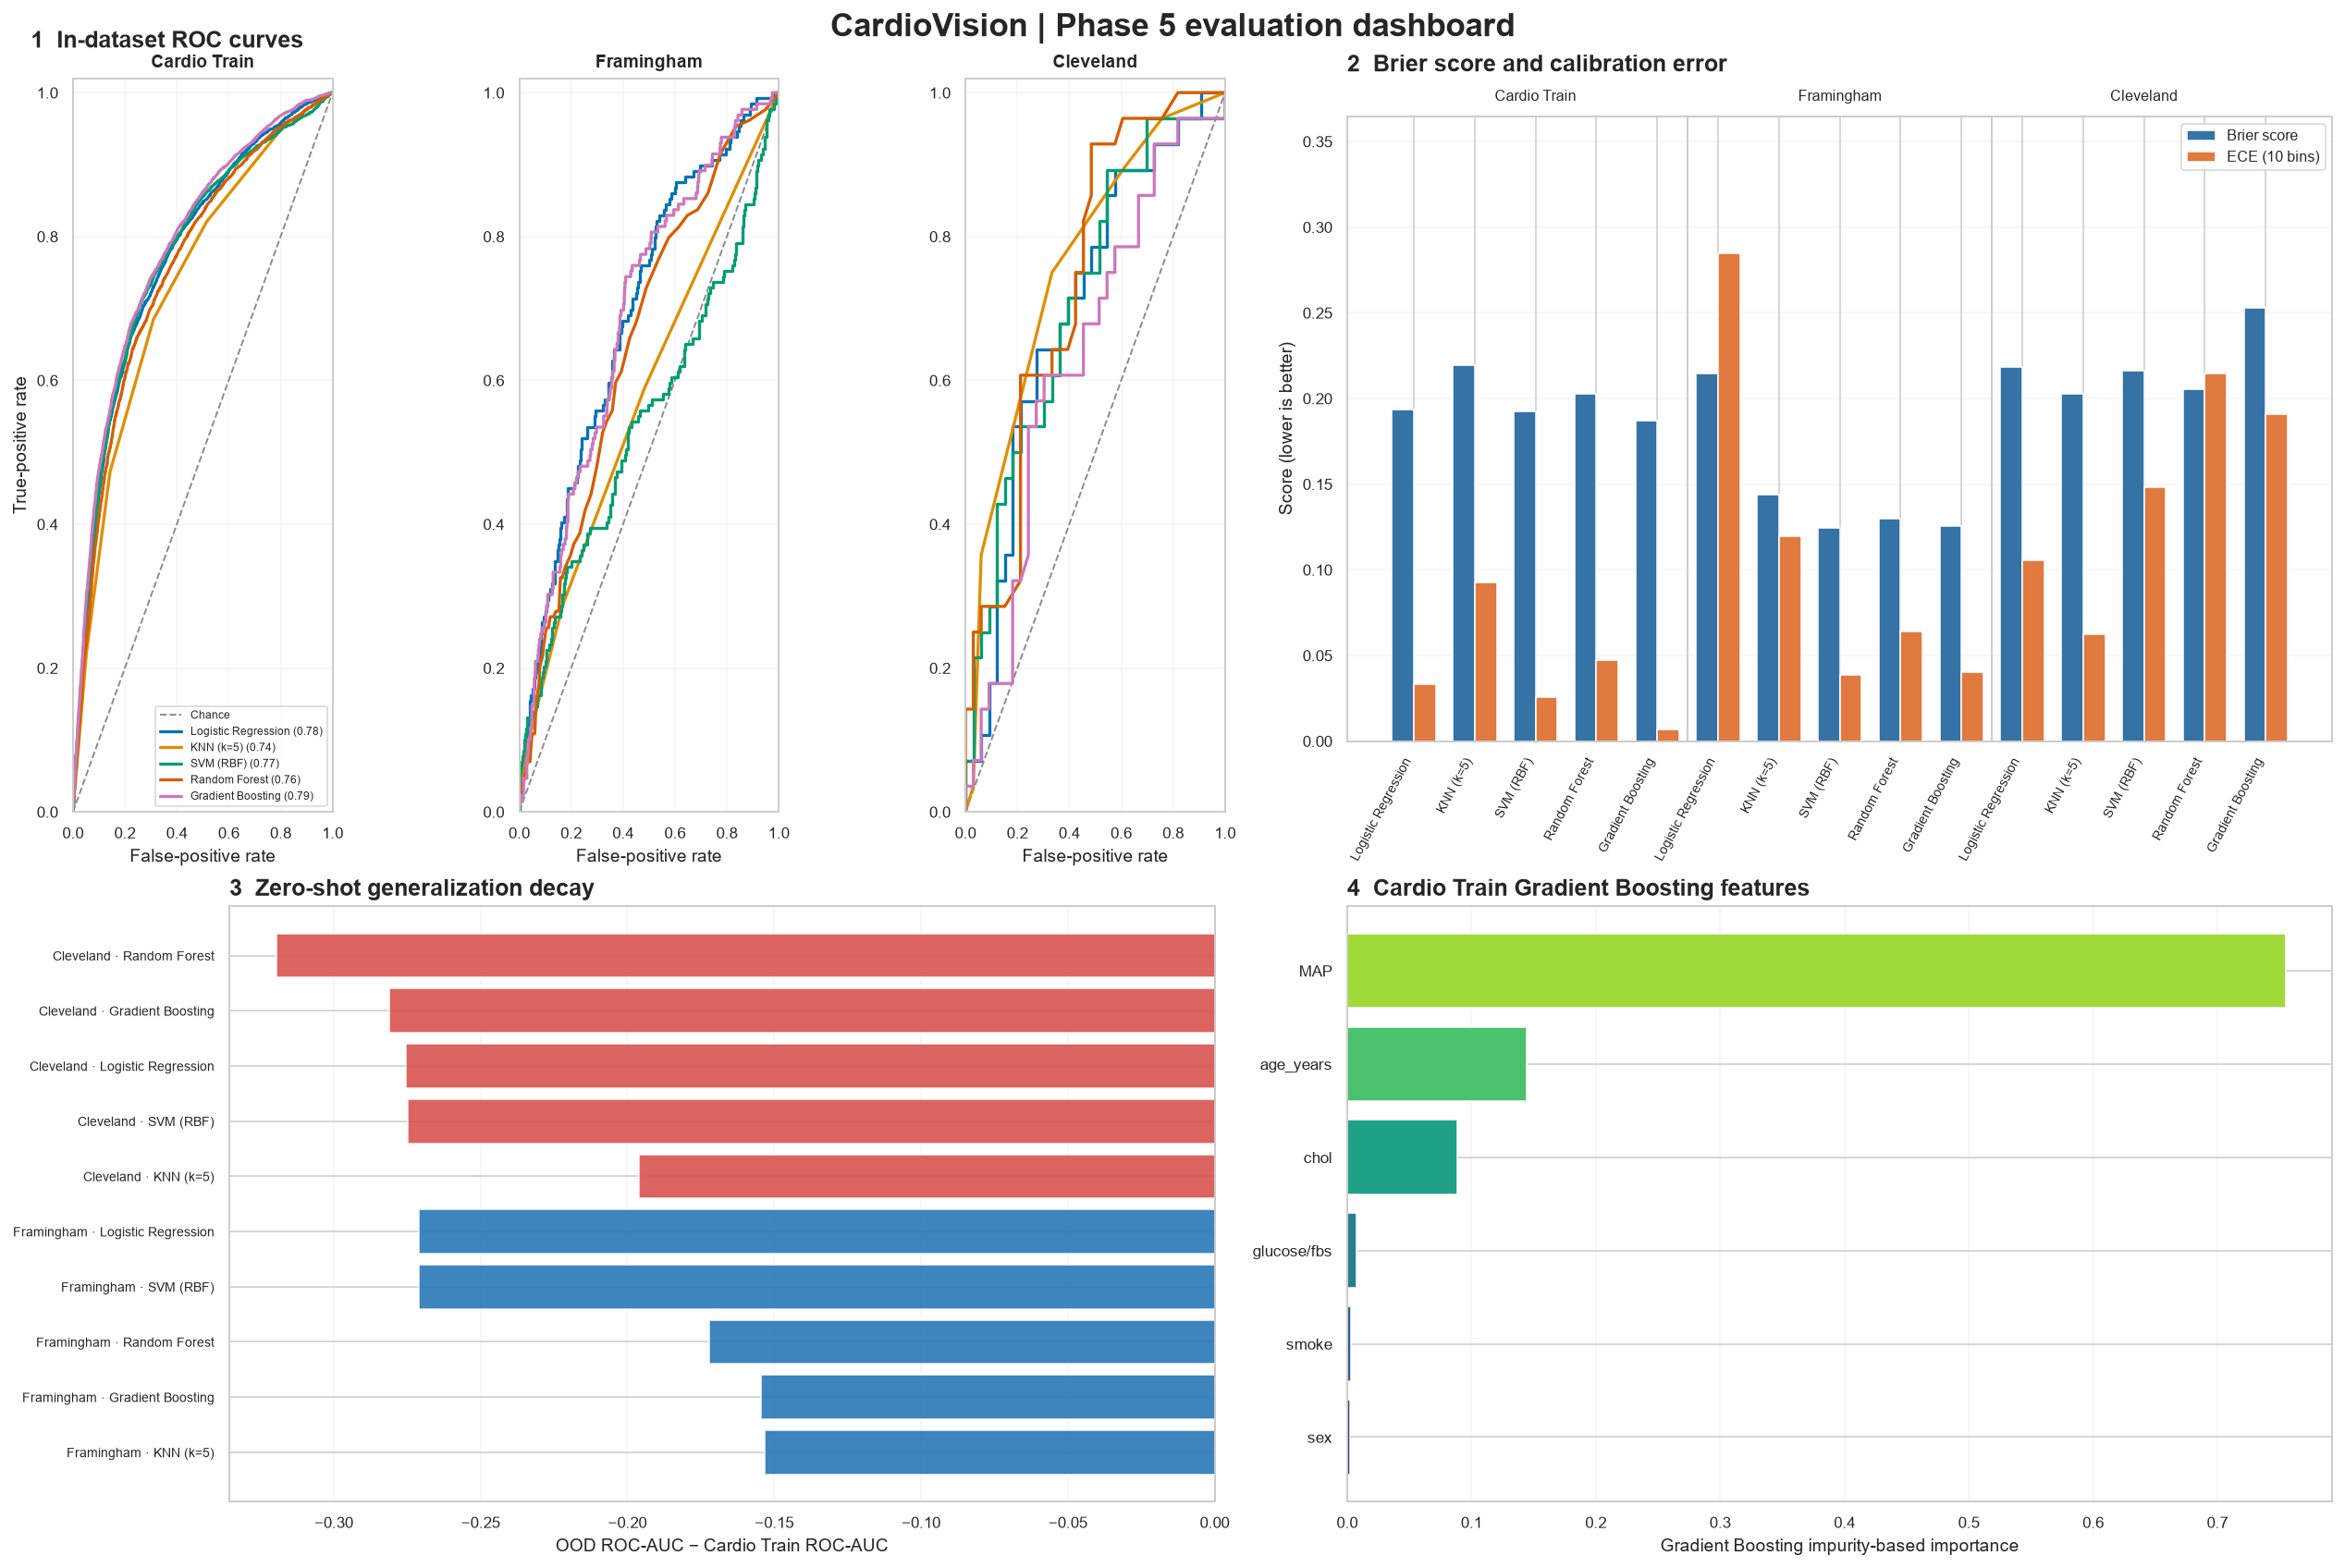

Saved publication-resolution dashboard to C:\Users\kunug\OneDrive\Desktop\cardioVision\result\final_evaluation_dashboard.png
Saved Cardio Train Gradient Boosting feature rankings to C:\Users\kunug\OneDrive\Desktop\cardioVision\result\cardio_gradient_boosting_feature_importance.csv


,dataset,dataset_key,model,fit_rows,accuracy,precision,recall,f1,roc_auc,brier_score,ece_10_quantile_bins
4,Cardio Train,cardio_train,Gradient Boosting,55008,0.7249,0.7340,0.6964,0.7147,0.7876,0.1868,0.0071
0,Cardio Train,cardio_train,Logistic Regression,55008,0.7186,0.7387,0.6675,0.7013,0.7755,0.1936,0.0334
2,Cardio Train,cardio_train,SVM (RBF),10000,0.7228,0.7354,0.6868,0.7103,0.7748,0.1922,0.0255
3,Cardio Train,cardio_train,Random Forest,55008,0.7066,0.7222,0.6616,0.6905,0.7595,0.2028,0.0471
1,Cardio Train,cardio_train,KNN (k=5),55008,0.6875,0.6840,0.6848,0.6844,0.7356,0.2192,0.0925
11,Cleveland,cleveland,KNN (k=5),242,0.7049,0.6562,0.7500,0.7000,0.7603,0.2026,0.0623
13,Cleveland,cleveland,Random Forest,242,0.6885,0.6800,0.6071,0.6415,0.7376,0.2054,0.2146
12,Cleveland,cleveland,SVM (RBF),242,0.6557,0.6522,0.5357,0.5882,0.7143,0.2164,0.1481
10,Cleveland,cleveland,Logistic Regression,242,0.6557,0.6400,0.5714,0.6038,0.7013,0.2181,0.1057
14,Cleveland,cleveland,Gradient Boosting,242,0.6557,0.6296,0.6071,0.6182,0.6380,0.2529,0.1909


,destination,model,cardio_test_roc_auc,ood_roc_auc,roc_auc_change
0,Framingham,Logistic Regression,0.7755,0.5045,-0.2710
1,Cleveland,Logistic Regression,0.7755,0.5000,-0.2755
2,Framingham,KNN (k=5),0.7356,0.5824,-0.1532
3,Cleveland,KNN (k=5),0.7356,0.5395,-0.1961
4,Framingham,SVM (RBF),0.7748,0.5039,-0.2710
5,Cleveland,SVM (RBF),0.7748,0.5000,-0.2748
6,Framingham,Random Forest,0.7595,0.5875,-0.1720
7,Cleveland,Random Forest,0.7595,0.4399,-0.3195
8,Framingham,Gradient Boosting,0.7876,0.6331,-0.1545
9,Cleveland,Gradient Boosting,0.7876,0.5065,-0.2811


,importance
MAP,0.7547
age_years,0.1441
chol,0.0884
glucose/fbs,0.0074
smoke,0.0034
sex,0.0021


In [3]:
# Read back the saved results so the figure is driven by portable result artifacts.
metrics = pd.read_csv(metrics_path)
zero_shot = pd.read_csv(zero_shot_path)
evaluation_arrays = dict(np.load(arrays_path, allow_pickle=False))

fig = plt.figure(figsize=(18, 12), constrained_layout=True)
outer = fig.add_gridspec(2, 2, height_ratios=[1.05, 1.0])
roc_grid = outer[0, 0].subgridspec(1, 3, wspace=0.18)
for dataset_index, dataset_name in enumerate(DATASETS):
    ax = fig.add_subplot(roc_grid[0, dataset_index])
    y_true = evaluation_arrays[f"{dataset_name}_y_test"]
    ax.plot([0, 1], [0, 1], linestyle="--", color="0.55", linewidth=1, label="Chance")
    for model_name in MODEL_NAMES:
        probabilities = evaluation_arrays[f"{dataset_name}__{model_name}__probabilities"]
        fpr, tpr, _ = roc_curve(y_true, probabilities)
        auc_value = roc_auc_score(y_true, probabilities)
        ax.plot(fpr, tpr, color=MODEL_COLORS[model_name], linewidth=1.7, label=f"{model_name} ({auc_value:.2f})")
    ax.set_title(DISPLAY_NAMES[dataset_name], fontsize=10)
    ax.set_xlabel("False-positive rate")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    ax.grid(alpha=0.2)
    if dataset_index == 0:
        ax.set_ylabel("True-positive rate")
        ax.legend(loc="lower right", fontsize=6.1, frameon=True)
fig.text(0.01, 0.985, "1  In-dataset ROC curves", fontsize=13, weight="bold", va="top")

ax_brier = fig.add_subplot(outer[0, 1])
bar_width = 0.36
x_positions = np.arange(len(DATASETS) * len(MODEL_NAMES))
bar_rows = metrics.set_index(["dataset_key", "model"])
ordered_rows = [bar_rows.loc[(dataset_name, model_name)] for dataset_name in DATASETS for model_name in MODEL_NAMES]
brier_values = [row["brier_score"] for row in ordered_rows]
ece_values = [row["ece_10_quantile_bins"] for row in ordered_rows]
ax_brier.bar(x_positions - bar_width / 2, brier_values, bar_width, label="Brier score", color="#3572A5")
ax_brier.bar(x_positions + bar_width / 2, ece_values, bar_width, label="ECE (10 bins)", color="#E07A3F")
ax_brier.set_xticks(x_positions)
ax_brier.set_xticklabels([model for _ in DATASETS for model in MODEL_NAMES], rotation=62, ha="right", fontsize=7)
for boundary in [4.5, 9.5]:
    ax_brier.axvline(boundary, color="0.75", linewidth=0.8)
for center, dataset_name in zip([2, 7, 12], DATASETS):
    ax_brier.text(center, 1.02, DISPLAY_NAMES[dataset_name], ha="center", va="bottom", fontsize=8, transform=ax_brier.get_xaxis_transform())
ax_brier.set_ylabel("Score (lower is better)")
ax_brier.set_ylim(0, max(max(brier_values), max(ece_values)) * 1.28)
ax_brier.set_title("2  Brier score and calibration error", loc="left", fontsize=13, weight="bold", pad=25)
ax_brier.legend(fontsize=8)
ax_brier.grid(axis="y", alpha=0.2)

ax_decay = fig.add_subplot(outer[1, 0])
plot_decay = zero_shot.copy()
plot_decay["label"] = plot_decay["destination"].str.replace("Framingham", "Framingham", regex=False) + " · " + plot_decay["model"]
plot_decay = plot_decay.sort_values(["destination", "roc_auc_change"], ascending=[True, True])
bar_colors = ["#2878B5" if destination == "Framingham" else "#D9534F" for destination in plot_decay["destination"]]
y_positions = np.arange(len(plot_decay))
ax_decay.barh(y_positions, plot_decay["roc_auc_change"], color=bar_colors, alpha=0.9)
ax_decay.axvline(0, color="0.25", linewidth=1)
ax_decay.set_yticks(y_positions)
ax_decay.set_yticklabels([f"{destination} · {model}" for destination, model in zip(plot_decay["destination"], plot_decay["model"])], fontsize=7.4)
ax_decay.set_xlabel("OOD ROC-AUC − Cardio Train ROC-AUC")
ax_decay.set_title("3  Zero-shot generalization decay", loc="left", fontsize=13, weight="bold")
ax_decay.grid(axis="x", alpha=0.2)
ax_decay.invert_yaxis()

ax_importance = fig.add_subplot(outer[1, 1])
gb = GradientBoostingClassifier(random_state=42)
gb.fit(preprocessed["cardio_train_harm_X_train"], preprocessed["cardio_train_y_train"])
feature_names = preprocessed["cardio_train_harm_feature_names"].tolist()
importance = pd.Series(gb.feature_importances_, index=feature_names).sort_values()
ax_importance.barh(importance.index, importance.values, color=sns.color_palette("viridis", len(importance)))
ax_importance.set_xlabel("Gradient Boosting impurity-based importance")
ax_importance.set_title("4  Cardio Train Gradient Boosting features", loc="left", fontsize=13, weight="bold")
ax_importance.grid(axis="x", alpha=0.2)

fig.suptitle("CardioVision | Phase 5 evaluation dashboard", fontsize=18, weight="bold")
dashboard_path = RESULT_DIR / "final_evaluation_dashboard.png"
fig.savefig(dashboard_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)
importance_path = RESULT_DIR / "cardio_gradient_boosting_feature_importance.csv"
importance.sort_values(ascending=False).rename("importance").to_csv(importance_path, header=True)
print(f"Saved publication-resolution dashboard to {dashboard_path}")
print(f"Saved Cardio Train Gradient Boosting feature rankings to {importance_path}")
display(metrics.sort_values(["dataset", "roc_auc"], ascending=[True, False]).round(4))
display(zero_shot[["destination", "model", "cardio_test_roc_auc", "ood_roc_auc", "roc_auc_change"]].round(4))
display(importance.sort_values(ascending=False).rename("importance").to_frame().round(4))

## Generate the final major-project executive report

In [4]:
def md_table(frame, columns):
    lines = ["| " + " | ".join(columns) + " |", "| " + " | ".join("---" for _ in columns) + " |"]
    for _, row in frame[columns].iterrows():
        values = []
        for column in columns:
            value = row[column]
            values.append(f"{value:.4f}" if isinstance(value, (float, np.floating)) else str(value))
        lines.append("| " + " | ".join(values) + " |")
    return "\n".join(lines)

best = metrics.loc[metrics.groupby("dataset")["roc_auc"].idxmax()].sort_values("dataset")
best_cardio = best.loc[best["dataset_key"] == "cardio_train"].iloc[0]
best_framingham = best.loc[best["dataset_key"] == "framingham"].iloc[0]
best_cleveland = best.loc[best["dataset_key"] == "cleveland"].iloc[0]
best_framingham_ood = zero_shot.loc[zero_shot["destination_key"] == "framingham", "roc_auc_change"].max()
best_cleveland_ood = zero_shot.loc[zero_shot["destination_key"] == "cleveland", "roc_auc_change"].max()
average_drop_framingham = -zero_shot.loc[zero_shot["destination_key"] == "framingham", "roc_auc_change"].mean()
average_drop_cleveland = -zero_shot.loc[zero_shot["destination_key"] == "cleveland", "roc_auc_change"].mean()
top_features = importance.sort_values(ascending=False).head(3)
class_lines = []
for dataset_name in DATASETS:
    y_train = preprocessed[f"{dataset_name}_y_train"]
    y_test = preprocessed[f"{dataset_name}_y_test"]
    class_lines.append(
        f"- **{DISPLAY_NAMES[dataset_name]}:** {len(y_train) + len(y_test):,} records; "
        f"stratified train/test sizes {len(y_train):,}/{len(y_test):,}; positive prevalence "
        f"{y_train.mean():.1%}/{y_test.mean():.1%}."
    )

report = [
    "# CardioVision: cross-dataset cardiovascular risk modeling",
    "",
    "**Major project report — Phases 1–5**  ",
    "**Evaluation artifact:** [final dashboard](../result/final_evaluation_dashboard.png)  ",
    "**Generated from:** `notebook/05_evaluation.ipynb`",
    "",
    "## Abstract & Problem Statement",
    "",
    "This project evaluates tabular cardiovascular risk classifiers across three public datasets: Cardio Train, Framingham, and the Cleveland heart-disease cohort. It combines source-specific cleaning with a six-feature shared representation, compares five binary classifiers using stratified held-out tests, assesses probability quality with Brier scores and calibration error, and probes transportability using zero-shot cross-dataset evaluation. The best held-out ROC-AUC was **{:.4f}** for Cardio Train ({}) , **{:.4f}** for Framingham ({}), and **{:.4f}** for Cleveland ({}). Transfer from Cardio Train to both external datasets reduced ROC-AUC for every model. These findings demonstrate why in-dataset discrimination alone is insufficient evidence for a portable clinical prediction model.".format(
        best_cardio["roc_auc"], best_cardio["model"], best_framingham["roc_auc"], best_framingham["model"], best_cleveland["roc_auc"], best_cleveland["model"]
    ),
    "",
    "The central problem is whether predictive performance measured within one cohort generalizes to populations with different feature distributions, measurement conventions, and outcome definitions. The study treats the cross-dataset experiment as an exploratory stress test, not as external clinical validation.",
    "",
    "## Literature Gap Analysis",
    "",
    "This project operationalizes three recurring evaluation risks in applied clinical machine learning; it is a project-level gap analysis, not a systematic literature review.",
    "",
    "1. **In-distribution overfitting and optimistic validation.** Random train/test partitions from the same source population can preserve cohort-specific patterns and do not establish transportability. A held-out split is necessary for benchmarking but should be supplemented by external validation.",
    "2. **Target mismatch across datasets.** Cardio disease status, Framingham ten-year coronary heart disease risk, and Cleveland disease presence represent related but non-identical endpoints. AUC differences across these datasets therefore reflect endpoint and cohort shifts together, not population shift alone.",
    "3. **Miscalibration hidden by discrimination metrics.** Ranking metrics such as ROC-AUC do not indicate whether predicted probabilities correspond to observed event frequencies. Brier scores and calibration curves add probability-quality evidence relevant to threshold-based decision support.",
    "",
    "## Methodology & Novelty Features",
    "",
    "- **Data preparation:** Cardio Train blood pressure was filtered using the prior physiological bounds; age in days was converted to integer years. Cleveland `?` markers in `ca`/`thal` were median-imputed, and disease severity was mapped to binary (`target > 0`). Framingham clinical predictors were median-imputed. Imputers and `StandardScaler` instances were fitted only on each training fold.",
    "- **Harmonized MAP feature engineering:** MAP was calculated as `DBP + (SBP - DBP) / 3` for Cardio Train and Framingham, enabling a shared pressure summary. Cleveland has only resting systolic pressure, so systolic pressure served as a clearly documented MAP proxy; it is not physiologically equivalent to true MAP.",
    "- **Shared input representation:** `age_years`, `sex`, `chol`, `glucose/fbs`, `MAP`, and `smoke`. Cardio sex codes were normalized to male=1/female=0. Cardio cholesterol/glucose are ordinal codes, Framingham uses measured concentrations, and Cleveland uses measured cholesterol plus fasting-glucose status. Cleveland lacks smoking; this field was imputed using the Cardio Train training-fold median for strict zero-shot application.",
    "- **Zero-shot OOD testing:** Cardio Train models and its fitted imputer/scaler were applied directly to held-out Framingham and Cleveland data without destination retraining or preprocessing refitting. This intentionally stringent transfer test captures both dataset and endpoint incompatibility.",
    "- **Calibration assessment:** Brier score and ten-quantile-bin calibration error (ECE) accompany ROC curves and classification metrics. The dashboard reports held-out predictions and a Gradient Boosting feature-importance ranking.",
    "",
    "## Experimental Setup & 5-Model Benchmark",
    "",
    "Each cohort used a reproducible stratified 80/20 train/test split (random state 42). Logistic Regression, 5-nearest neighbors, RBF-kernel SVM with probability estimates, a 100-tree Random Forest, and Gradient Boosting were compared. Framingham Logistic Regression used balanced class weights. The RBF SVM used a reproducible stratified 10,000-row training subset when fitting on the large Cardio cohort; all models were evaluated on the full held-out test set. Precision, recall, and F1 use a 0.5 probability threshold.",
    "",
    *class_lines,
    "",
    "## Results & Discussion",
    "",
    "### In-dataset benchmark",
    "",
    md_table(metrics, ["dataset", "model", "accuracy", "precision", "recall", "f1", "roc_auc", "brier_score", "ece_10_quantile_bins"]),
    "",
    f"The top in-dataset model by ROC-AUC was **{best_cardio['model']}** on Cardio Train (AUC {best_cardio['roc_auc']:.4f}, Brier {best_cardio['brier_score']:.4f}), **{best_framingham['model']}** on Framingham (AUC {best_framingham['roc_auc']:.4f}, Brier {best_framingham['brier_score']:.4f}), and **{best_cleveland['model']}** on Cleveland (AUC {best_cleveland['roc_auc']:.4f}, Brier {best_cleveland['brier_score']:.4f}). Framingham has a lower positive prevalence ({preprocessed['framingham_y_test'].mean():.1%} in its test set), so accuracy and ROC-AUC should be interpreted alongside recall, precision, and calibration rather than in isolation.",
    "",
    "### Zero-shot transfer",
    "",
    md_table(zero_shot, ["destination", "model", "cardio_test_roc_auc", "ood_roc_auc", "roc_auc_change", "accuracy", "precision", "recall", "f1", "brier_score"]),
    "",
    f"All ten zero-shot comparisons had lower ROC-AUC than the corresponding Cardio Train baseline. The least negative transfer changes were {best_framingham_ood:.4f} to Framingham and {best_cleveland_ood:.4f} to Cleveland. Average ROC-AUC drops across the five Cardio-trained models were {average_drop_framingham:.4f} and {average_drop_cleveland:.4f}, respectively. The Cardio Train Gradient Boosting transfer AUCs were {zero_shot.loc[(zero_shot['destination_key'] == 'framingham') & (zero_shot['model'] == 'Gradient Boosting'), 'ood_roc_auc'].iloc[0]:.4f} for Framingham and {zero_shot.loc[(zero_shot['destination_key'] == 'cleveland') & (zero_shot['model'] == 'Gradient Boosting'), 'ood_roc_auc'].iloc[0]:.4f} for Cleveland. The dashboard shows all model-by-destination ROC-AUC changes.",
    "",
    "These results are consistent with substantial distribution and label shift, but do not isolate their individual causal contributions. In particular, the Cleveland proxy features and distinct disease endpoint limit direct clinical comparability. ROC-AUC drop indicates ranking degradation; destination Brier scores and calibration behavior also shift, so source-cohort probability interpretation should not be carried over to the external cohorts.",
    "",
    "### Feature ranking",
    "",
    "For the Cardio Train Gradient Boosting model, the three largest impurity-based feature importances were: " + ", ".join(f"`{name}` ({value:.3f})" for name, value in top_features.items()) + ". These are model-specific predictive associations, not causal effects or clinical risk factors ranked across cohorts.",
    "",
    "## Clinical Decision Support & Future Scope",
    "",
    "The current models are research prototypes and must not be used to diagnose, rule out disease, recommend treatment, or replace clinician judgment. Before decision-support use, a model would require prespecified target definitions, clinically equivalent input measurements, representative prospective external cohorts, subgroup and fairness analyses, confidence intervals, calibration assessment and (if justified) recalibration, threshold/utility analysis, human-factors testing, governance, and ongoing drift monitoring. Missingness patterns and dataset provenance must be documented for each deployed source.",
    "",
    "Future work should (1) align outcomes and prediction horizons, (2) validate on independent contemporary cohorts with consistent laboratory and blood-pressure protocols, (3) compare recalibration and domain-adaptation approaches only after retaining a strict untouched external test set, (4) estimate uncertainty using repeated or nested validation and bootstrap intervals, (5) evaluate decision-curve/net-benefit measures and subgroup performance, and (6) develop a versioned, auditable pipeline with clinician input and post-deployment safety monitoring.",
    "",
    "## Reproducibility and Artifacts",
    "",
    "- Evaluation notebook: `../notebook/05_evaluation.ipynb`.",
    "- Four-panel dashboard: `../result/final_evaluation_dashboard.png`.",
    "- In-dataset metrics: `../result/evaluation_metrics.csv`.",
    "- Zero-shot metrics: `../result/evaluation_zero_shot_metrics.csv`.",
    "- Test probabilities and targets: `../result/evaluation_performance_arrays.npz`.",
    "- Cardio Train Gradient Boosting feature ranking: `../result/cardio_gradient_boosting_feature_importance.csv`.",
    "",
]
report_path = REPORT_DIR / "CardioVision_Major_Project_Report.md"
report_path.write_text("\n".join(report), encoding="utf-8")
print(f"Wrote executive report: {report_path}")
print(f"Top Cardio Train features: {top_features.to_dict()}")
print(f"Zero-shot mean ROC-AUC drops: Framingham={average_drop_framingham:.4f}; Cleveland={average_drop_cleveland:.4f}")

Wrote executive report: C:\Users\kunug\OneDrive\Desktop\cardioVision\report\CardioVision_Major_Project_Report.md
Top Cardio Train features: {'MAP': 0.7546679515648874, 'age_years': 0.14408182138213277, 'chol': 0.08840026410552222}
Zero-shot mean ROC-AUC drops: Framingham=0.2043; Cleveland=0.2694
